# Simple Example on Using the CutPrimitives

In [2]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer import AerSimulator

from QCut import CutOptions
from QCut.primitives import CutEstimator, CutQuasiSampler
from QCut.QCutFind import find_cuts


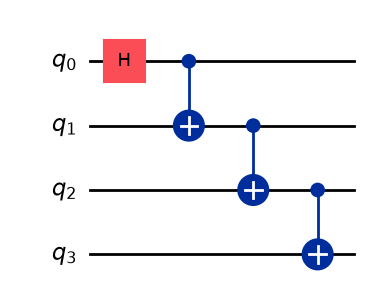

In [3]:
qc = QuantumCircuit(4)
qc.h(0)
for i in range(1,4):
    qc.cx(i-1,i)

qc.draw("mpl")

In [4]:
observables = SparsePauliOp.from_list([("IIIZ", 1), ("IIXI", 1), ("IYII", 1), ("ZIII", 1)])

In [5]:
backend = AerSimulator()

In [6]:
estimator = CutEstimator(backend)

In [7]:
options = CutOptions(finder_max_qubits=2, finder_num_partitions=2)

In [8]:
cut_circuit = find_cuts(qc, options)

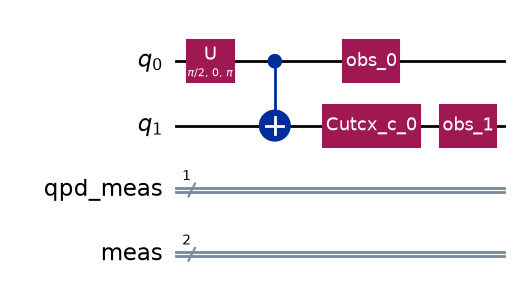

In [9]:
cut_circuit.subcircuits[0].draw("mpl")

In [10]:
from qiskit.primitives import StatevectorEstimator

svestimator = StatevectorEstimator()

In [11]:
import numpy as np
from qiskit.primitives import BackendEstimatorV2

shots = 2**12
labels = observables.paulis.to_labels() + ["sum"]
terms = [SparsePauliOp(label) for label in observables.paulis.to_labels()] + [observables]

cut_job = estimator.run(cut_circuit, terms, shots=shots)
cut_values, cut_errors = cut_job.expectation_values(0), cut_job.standard_errors(0)

aer_estimator = BackendEstimatorV2(backend=AerSimulator())
aer_data = aer_estimator.run([(qc, terms)], precision=1 / np.sqrt(shots)).result()[0].data
aer_values, aer_errors = aer_data.evs, aer_data.stds

exact_values = svestimator.run([(qc, terms)]).result()[0].data.evs

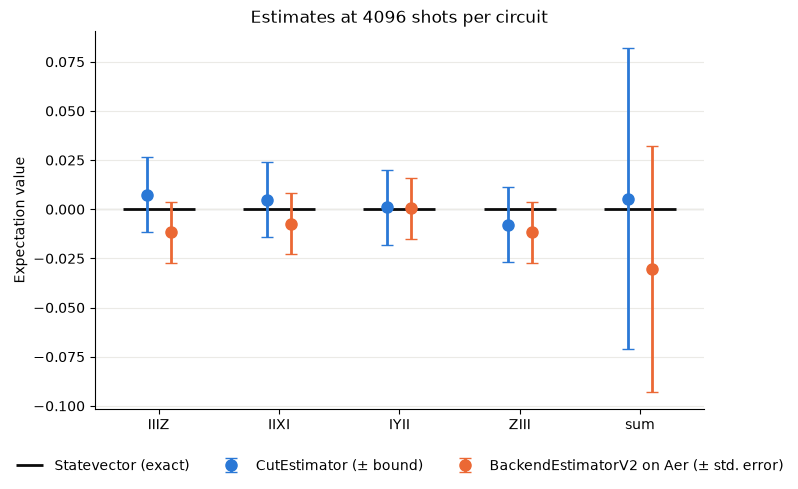

In [12]:
import matplotlib.pyplot as plt

x = np.arange(len(labels))
fig, ax = plt.subplots(figsize=(8, 5))
ax.axhline(0, color="#d4d3cf", linewidth=1, zorder=0)
ax.hlines(
    exact_values, x - 0.3, x + 0.3, color="#0b0b0b", linewidth=2, label="Statevector (exact)"
)
ax.errorbar(
    x - 0.1, cut_values, yerr=cut_errors, fmt="o", markersize=8, color="#2a78d6",
    elinewidth=2, capsize=4, label="CutEstimator (± bound)",
)
ax.errorbar(
    x + 0.1, aer_values, yerr=aer_errors, fmt="o", markersize=8, color="#eb6834",
    elinewidth=2, capsize=4, label="BackendEstimatorV2 on Aer (± std. error)",
)
ax.set_xticks(x, labels)
ax.set_ylabel("Expectation value")
ax.set_title(f"Estimates at {shots} shots per circuit")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3)
fig.tight_layout()
plt.show()

In [13]:
from qiskit.circuit import Parameter

theta = Parameter("theta")
pqc = QuantumCircuit(4)
pqc.ry(theta, 0)
for i in range(1,4):
    pqc.cx(i-1,i)

cut_pqc = find_cuts(pqc, options)
thetas = np.linspace(0, np.pi, 5)

In [ ]:
sweep_job = estimator.run(
    [cut_pqc] * len(thetas), observables, shots=shots,
    parameter_values=[{theta: t} for t in thetas],
)
sweep_values = np.array(sweep_job.expectation_values())
sweep_errors = np.array(sweep_job.standard_errors())

fine_thetas = np.linspace(0, np.pi, 100)
exact_sweep = svestimator.run([(pqc, observables, fine_thetas[:, None])]).result()[0].data.evs

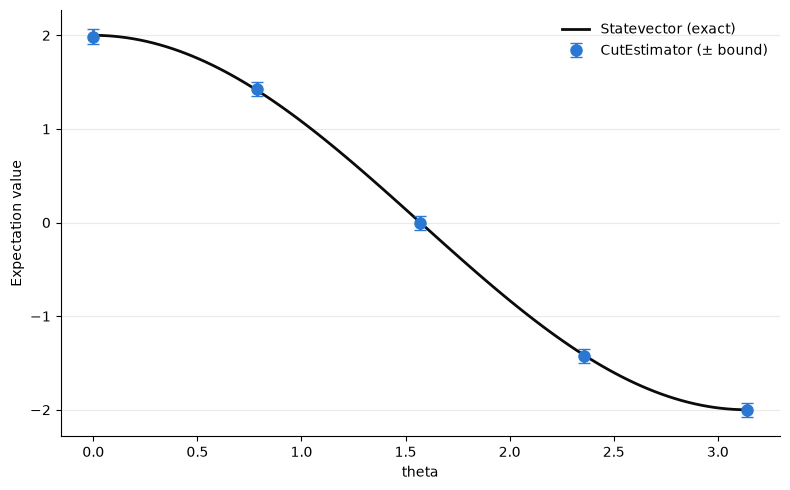

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(fine_thetas, exact_sweep, color="#0b0b0b", linewidth=2, label="Statevector (exact)")
ax.errorbar(
    thetas, sweep_values, yerr=sweep_errors, fmt="o", markersize=8, color="#2a78d6",
    elinewidth=2, capsize=4, label="CutEstimator (± bound)",
)
ax.set_xlabel("theta")
ax.set_ylabel("Expectation value")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#ebeae6", linewidth=0.8)
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

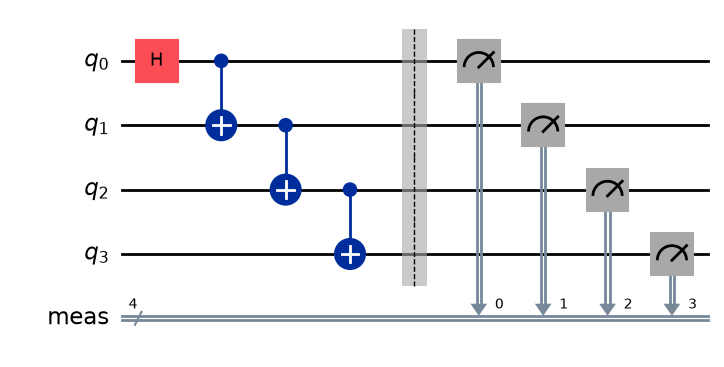

In [16]:
qc_meas = qc.measure_all()

qc.draw("mpl")

In [17]:
sampler = CutQuasiSampler(backend)

In [18]:
from qiskit.quantum_info import Statevector
from qiskit_aer.primitives import SamplerV2

unmeasured = qc.remove_final_measurements(inplace=False)
measured = unmeasured.measure_all(inplace=False)

bitstrings = [format(x, f"0{measured.num_qubits}b") for x in range(2**measured.num_qubits)]

cut_measured = find_cuts(measured, options)
cut_entry = sampler.run(cut_measured, shots=shots).result()[0]
cut_probs = np.array([cut_entry.quasi_probabilities[b] for b in bitstrings])
cut_prob_error = cut_entry.standard_error  # one bound, the same for every bitstring

aer_counts = SamplerV2().run([measured], shots=shots).result()[0].data.meas.get_counts()
aer_probs = np.array([aer_counts.get(b, 0) / shots for b in bitstrings])
aer_prob_errors = np.sqrt(aer_probs * (1 - aer_probs) / shots)

exact_probs = Statevector(unmeasured).probabilities()

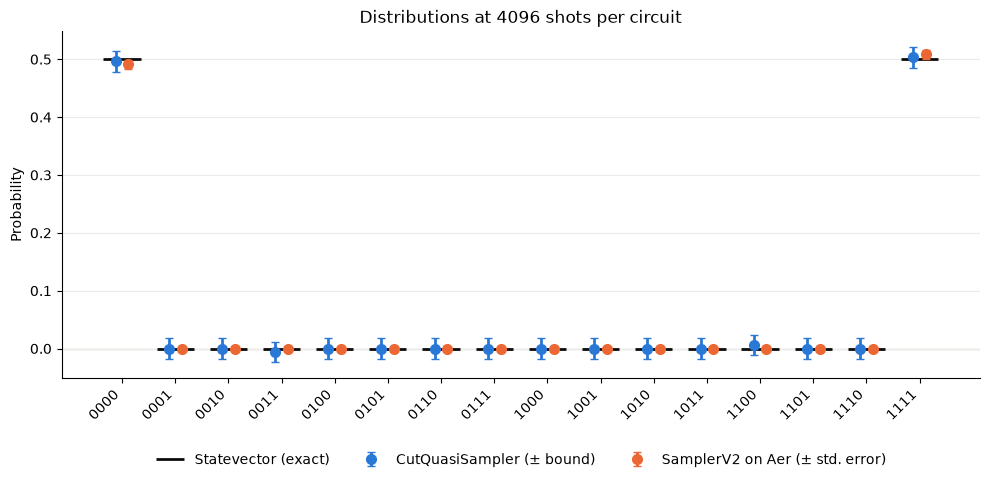

In [19]:
x = np.arange(len(bitstrings))
fig, ax = plt.subplots(figsize=(10, 5))
ax.axhline(0, color="#d4d3cf", linewidth=1, zorder=0)
ax.hlines(
    exact_probs, x - 0.35, x + 0.35, color="#0b0b0b", linewidth=2, label="Statevector (exact)"
)
ax.errorbar(
    x - 0.12, cut_probs, yerr=cut_prob_error, fmt="o", markersize=7, color="#2a78d6",
    elinewidth=2, capsize=3, label="CutQuasiSampler (± bound)",
)
ax.errorbar(
    x + 0.12, aer_probs, yerr=aer_prob_errors, fmt="o", markersize=7, color="#eb6834",
    elinewidth=2, capsize=3, label="SamplerV2 on Aer (± std. error)",
)
ax.set_xticks(x, bitstrings, rotation=45, ha="right")
ax.set_ylabel("Probability")
ax.set_title(f"Distributions at {shots} shots per circuit")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#ebeae6", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=3)
fig.tight_layout()
plt.show()